# Football Metrics & Performance Comparison Engine
**Proyecto de Analítica Deportiva y Visualización de Datos en Fútbol**

### Objetivo
Extraer, procesar y comparar cuantitativamente el rendimiento individual y el contexto táctico de dos futbolistas a partir de eventos de juego. El análisis evalúa diferentes dimensiones del rendimiento (ofensiva, creación, regate y contribución defensiva) mediante métricas agregadas y representaciones gráficas avanzadas (diagramas de radar/pizza).

En este estudio de caso, se realiza una comparativa directa entre **Antoine Griezmann** (Atlético de Madrid) y **Neymar Jr** (FC Barcelona) durante la temporada **LaLiga 2015/2016**.

* **Stack:** Python, StatsBomb Open Data, Pandas, NumPy, Mplsoccer, Matplotlib.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsbombpy import sb
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from mplsoccer import PyPizza

# Configuración visual
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 0. Exploración de Competiciones Disponibles
Consultamos el catálogo de datos abiertos de StatsBomb mediante `sb.competitions()` para identificar los códigos de competición (`competition_id`) y temporada (`season_id`). En este estudio utilizaremos **LaLiga 2015/2016** (`competition_id = 11`, `season_id = 27`).

In [3]:
from statsbombpy import sb
import pandas as pd

# Listar todas las competiciones abiertas
competitions = sb.competitions()
print(competitions[['competition_id', 'season_id', 'competition_name', 'season_name']])

    competition_id  season_id         competition_name season_name
0                9        281            1. Bundesliga   2023/2024
1                9         27            1. Bundesliga   2015/2016
2             1267        107   African Cup of Nations        2023
3               16          4         Champions League   2018/2019
4               16          1         Champions League   2017/2018
5               16          2         Champions League   2016/2017
6               16         27         Champions League   2015/2016
7               16         26         Champions League   2014/2015
8               16         25         Champions League   2013/2014
9               16         24         Champions League   2012/2013
10              16         23         Champions League   2011/2012
11              16         22         Champions League   2010/2011
12              16         21         Champions League   2009/2010
13              16         41         Champions League   2008/

## 1. Ingesta y Extracción de Datos
Descargamos y concatenamos los eventos de todos los partidos jugados en **LaLiga 2015/2016** (`competition_id = 11`, `season_id = 27`) para dos clubes clave:

1. **Atlético de Madrid:** Se filtran las acciones de Antoine Griezmann.
2. **FC Barcelona:** Se filtran las acciones de Neymar Jr.

In [ ]:
from statsbombpy import sb
import pandas as pd
import numpy as np

# 1. Obtener partidos de LaLiga 2015/16 (competition_id=11, season_id=27)
matches = sb.matches(competition_id=11, season_id=27)

# 2. Filtrar partidos del Atlético de Madrid
atleti_matches = matches[(matches['home_team'] == 'Atlético Madrid') | (matches['away_team'] == 'Atlético Madrid')].copy()
atleti_match_ids = atleti_matches['match_id'].tolist()

print(f"Total de partidos del Atleti en 2015/16 disponibles: {len(atleti_match_ids)}")

# 3. Descargar eventos de los partidos (para probar rápido, puedes tomar match_ids[:10] o todos los disponibles)
print("Descargando eventos de los partidos del Atlético de Madrid...")
atleti_events_list = []

for m_id in atleti_match_ids:
    df_m = sb.events(match_id=m_id)
    atleti_events_list.append(df_m)

df_atleti = pd.concat(atleti_events_list, ignore_index=True)

griezmann_events = df_atleti[df_atleti['player'] == 'Antoine Griezmann'].copy()
print(f"Total de acciones registradas de Griezmann en LaLiga 15/16: {len(griezmann_events):,}")

Total de partidos del Atleti en 2015/16 disponibles: 38
Descargando eventos de los partidos del Atlético de Madrid...
Total de acciones registradas de Griezmann en LaLiga 15/16: 6,012


In [16]:
# 1. Filtrar partidos del FC Barcelona en LaLiga 2015/16
barca_matches = matches[(matches['home_team'] == 'Barcelona') | (matches['away_team'] == 'Barcelona')].copy()
barca_match_ids = barca_matches['match_id'].tolist()

print(f"Partidos del Barcelona disponibles: {len(barca_match_ids)}")

# 2. Descargar eventos del Barça
print("Descargando eventos del Barcelona...")
barca_events_list = []
for m_id in barca_match_ids:
    df_m = sb.events(match_id=m_id)
    barca_events_list.append(df_m)

df_barca = pd.concat(barca_events_list, ignore_index=True)

# 3. Filtrar eventos de Neymar
neymar_events = df_barca[df_barca['player'] == 'Neymar da Silva Santos Junior'].copy()
print(f"Eventos registrados de Neymar en LaLiga 15/16: {len(neymar_events):,}")

Partidos del Barcelona disponibles: 38
Descargando eventos del Barcelona...
Eventos registrados de Neymar en LaLiga 15/16: 8,238


## 2. Cálculo de Métricas Individuales
Implementamos una función unificada (`calcular_metricas`) para agregar los eventos individuales en variables sintéticas divididas en cuatro dimensiones competitivas:

* **Efectividad Ofensiva:** Goles, Goles Esperados (xG) y % de Puntería a puerta.
* **Creación de Juego:** Pases Clave (asistencias de disparo) y % de Precisión en Pases.
* **Capacidad de Desborde:** Regates Completados y % de Éxito en el Regate.
* **Compromiso Defensivo:** Acciones de Presión y Recuperaciones de balón.

In [17]:
def calcular_metricas(df_jugador):
    # Tiros
    s = df_jugador[df_jugador['type'] == 'Shot']
    tot_s = len(s)
    goals = len(s[s['shot_outcome'] == 'Goal'])
    s_target = len(s[s['shot_outcome'].isin(['Goal', 'Saved', 'Saved to Post', 'Post'])])
    acc_shot = (s_target / tot_s * 100) if tot_s > 0 else 0
    xg = s['shot_statsbomb_xg'].sum() if 'shot_statsbomb_xg' in s.columns else 0

    # Pases
    p = df_jugador[df_jugador['type'] == 'Pass']
    tot_p = len(p)
    comp_p = len(p[p['pass_outcome'].isna()])
    acc_pass = (comp_p / tot_p * 100) if tot_p > 0 else 0
    key_p = len(p[p['pass_shot_assist'] == True]) if 'pass_shot_assist' in p.columns else 0

    # Regates
    d = df_jugador[df_jugador['type'] == 'Dribble']
    tot_d = len(d)
    comp_d = len(d[d['dribble_outcome'] == 'Complete'])
    acc_drib = (comp_d / tot_d * 100) if tot_d > 0 else 0

    # Acciones defensivas
    press = len(df_jugador[df_jugador['type'] == 'Pressure'])
    recov = len(df_jugador[df_jugador['type'] == 'Ball Recovery'])

    return {
        'Goles': goals,
        'xG': round(xg, 1),
        '% Puntería': round(acc_shot, 1),
        'Pases Clave': key_p,
        '% Prec. Pase': round(acc_pass, 1),
        'Regates Compl.': comp_d,
        '% Éxito Regate': round(acc_drib, 1),
        'Presiones': press,
        'Recuperaciones': recov
    }

m_griezmann = calcular_metricas(griezmann_events)
m_neymar = calcular_metricas(neymar_events)

# Mostramos tabla comparativa
df_comparativa = pd.DataFrame([m_griezmann, m_neymar], index=['Antoine Griezmann', 'Neymar Jr'])
print(df_comparativa.T)

                Antoine Griezmann  Neymar Jr
Goles                        22.0       24.0
xG                           16.0       20.5
% Puntería                   50.0       50.4
Pases Clave                  49.0       82.0
% Prec. Pase                 78.4       77.8
Regates Compl.               46.0      169.0
% Éxito Regate               56.1       61.9
Presiones                   619.0      392.0
Recuperaciones              167.0      134.0


## 3. Análisis del Contexto Colectivo y Volumen de Juego
Comparar valores absolutos entre futbolistas de equipos con estilos tácticos opuestos introduce un sesgo de volumen. 

El **FC Barcelona** maneja un volumen masivo de posesión (media de 1,964.9 acciones/partido), mientras que el **Atlético de Madrid** opera bajo un esquema defensivo/transicional (1,409.2 acciones/partido). Calculamos el porcentaje de cuota de juego (*usage rate* o *share*) que representa cada jugador dentro de la estructura colectiva de su equipo.

In [18]:
import pandas as pd

# 1. Definir los tipos de evento que implican posesión/contacto con balón
on_ball_types = ['Pass', 'Ball Receipt*', 'Carry', 'Shot', 'Dribble', 'Miscontrol', 'Dispossessed']

# 2. Filtrar acciones con balón de cada equipo en sus respectivos datasets
# Acciones con balón del Atlético de Madrid
atleti_on_ball = df_atleti[(df_atleti['team'] == 'Atlético Madrid') & (df_atleti['type'].isin(on_ball_types))]
total_atleti_actions = len(atleti_on_ball)

# Acciones con balón del FC Barcelona
barca_on_ball = df_barca[(df_barca['team'] == 'Barcelona') & (df_barca['type'].isin(on_ball_types))]
total_barca_actions = len(barca_on_ball)

# 3. Acciones con balón de Griezmann y Neymar
griezmann_on_ball = atleti_on_ball[atleti_on_ball['player'] == 'Antoine Griezmann']
neymar_on_ball = barca_on_ball[barca_on_ball['player'] == 'Neymar da Silva Santos Junior']

# 4. Cálculo de ratios y métricas colectivas
n_partidos_atleti = len(atleti_match_ids)
n_partidos_barca = len(barca_match_ids)

atleti_actions_p90 = total_atleti_actions / n_partidos_atleti
barca_actions_p90 = total_barca_actions / n_partidos_barca

griezmann_share = (len(griezmann_on_ball) / total_atleti_actions) * 100
neymar_share = (len(neymar_on_ball) / total_barca_actions) * 100

# 5. Imprimir comparativa de contexto táctico
print("="*65)
print("CONTEXTO COLECTIVO: VOLUMEN DE JUEGO CON BALÓN (LALIGA 15/16)")
print("="*65)
print(f"FC BARCELONA:")
print(f"• Total acciones con balón: {total_barca_actions:,}")
print(f"• Media de acciones con balón por partido: {barca_actions_p90:.1f}")
print(f"• Acciones de Neymar: {len(neymar_on_ball):,} ({neymar_share:.2f}% del volumen total del Barça)")
print("-" * 65)
print(f"ATLÉTICO DE MADRID:")
print(f"• Total acciones con balón: {total_atleti_actions:,}")
print(f"• Media de acciones con balón por partido: {atleti_actions_p90:.1f}")
print(f"• Acciones de Griezmann: {len(griezmann_on_ball):,} ({griezmann_share:.2f}% del volumen total del Atleti)")
print("="*65)

CONTEXTO COLECTIVO: VOLUMEN DE JUEGO CON BALÓN (LALIGA 15/16)
FC BARCELONA:
• Total acciones con balón: 74,665
• Media de acciones con balón por partido: 1964.9
• Acciones de Neymar: 7,357 (9.85% del volumen total del Barça)
-----------------------------------------------------------------
ATLÉTICO DE MADRID:
• Total acciones con balón: 53,550
• Media de acciones con balón por partido: 1409.2
• Acciones de Griezmann: 4,796 (8.96% del volumen total del Atleti)


## 4. Visualización de Perfiles con Diagramas de Radar
Utilizamos la librería `mplsoccer` para representar visualmente el perfil percentilar de ambos jugadores. Esta representación gráfica ayuda a validar la idoneidad de usar distancias métricas (como la similitud del coseno o KNN) para recomendar sustitutos o perfiles homólogos.

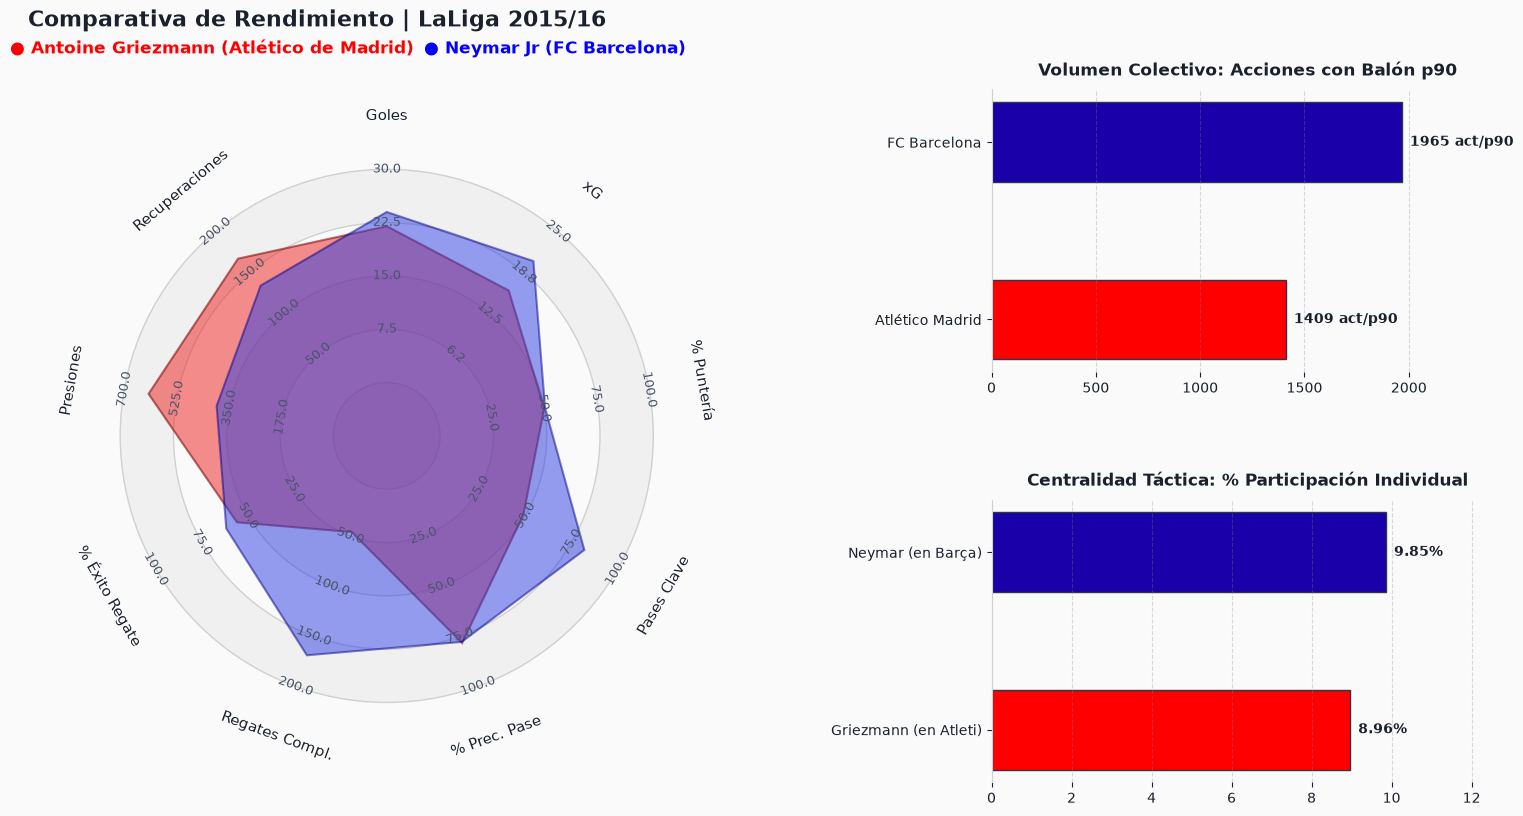

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mplsoccer import Radar, FontManager

params = list(m_griezmann.keys())

# Valores reales de la tabla
valores_griezmann = list(m_griezmann.values())
valores_neymar    = list(m_neymar.values())
valores_equipo = [atleti_actions_p90, barca_actions_p90]
valores_cuota = [griezmann_share, neymar_share]

# 2. Definir límites (mínimos en 0 y máximos holgados para cada métrica)
low =  [0,    0,    0,   0,   0,   0,   0,   0,   0]
high = [30,  25,  100, 100, 100, 200, 100, 700, 200]


# 4. Configurar la figura (fondo claro similar a la referencia)
fig = plt.figure(figsize=(18, 9), facecolor='#FAFAFA')

# Dividimos el espacio en 2 filas y 2 columnas:
# Columna 0 (ancho 1.4): Radar
# Columna 1 (ancho 1.0): Barras superiores (Fila 0) y Barras inferiores (Fila 1)
gs = gridspec.GridSpec(2, 2, width_ratios=[1.4, 1.0], left=0.08, right=0.90, height_ratios=[1, 1], wspace=0.40, hspace=0.45)
ax_hueco_radar = fig.add_subplot(gs[:, 0])
ax_bar1  = fig.add_subplot(gs[0, 1], facecolor='#FAFAFA')
ax_bar2  = fig.add_subplot(gs[1, 1], facecolor='#FAFAFA')

# 3. Inicializar el objeto Radar
radar = Radar(
    params=params,
    min_range=low,
    max_range=high,
    num_rings=4,
    ring_width=1,
    center_circle_radius=1
)

radar.setup_axis(ax=ax_hueco_radar, facecolor='#FAFAFA')
# Dibujar anillos concéntricos y radios
radar.draw_circles(ax=ax_hueco_radar, facecolor='#F0F0F0', edgecolor='#D0D0D0')

# 5. Dibujar polígonos semitransparentes
radar.draw_radar_compare(
    valores_griezmann, valores_neymar, ax=ax_hueco_radar,
    kwargs_radar={'facecolor': "#EE3030", 'alpha': 0.55, 'edgecolor': "#7A0000", 'linewidth': 1.5},
    kwargs_compare={'facecolor': "#2B3EE2", 'alpha': 0.50, 'edgecolor': "#04018A", 'linewidth': 1.5}
)

# 6. Etiquetas numéricas intermedias y nombres de los ejes
radar.draw_range_labels(ax=ax_hueco_radar, fontsize=9, color='#4A5568')
radar.draw_param_labels(ax=ax_hueco_radar, fontsize=11, color='#1A202C', offset=1)

# -------------------------------------------------------------
# 5. GRÁFICOS DE BARRAS HORIZONTALES (ax.barh)
# -------------------------------------------------------------
colores = ["#FF0000", "#1900A8"]

# Barra 1: Acciones con balón del equipo por partido (Contexto de posesión)
equipos = ['Atlético Madrid', 'FC Barcelona']

barras1 = ax_bar1.barh(equipos, valores_equipo, color=colores, height=0.45, edgecolor='#2D3748')
ax_bar1.set_title("Volumen Colectivo: Acciones con Balón p90", fontsize=12, weight='bold', color='#1A202C', pad=10)
ax_bar1.set_xlim(0, max(valores_equipo) * 1.25)
ax_bar1.bar_label(barras1, fmt='%.0f act/p90', padding=6, fontsize=10, color='#1A202C', weight='bold')

# Barra 2: Cuota de intervención del jugador sobre su equipo (%)
etiquetas_jugador = ['Griezmann (en Atleti)', 'Neymar (en Barça)']

barras2 = ax_bar2.barh(etiquetas_jugador, valores_cuota, color=colores, height=0.45, edgecolor='#2D3748')
ax_bar2.set_title("Centralidad Táctica: % Participación Individual", fontsize=12, weight='bold', color='#1A202C', pad=10)
ax_bar2.set_xlim(0, max(valores_cuota) * 1.3)
ax_bar2.bar_label(barras2, fmt='%.2f%%', padding=6, fontsize=10, color='#1A202C', weight='bold')

#Limpieza visual

for ax in [ax_bar1, ax_bar2]:
    ax.tick_params(colors='#1A202C', labelsize=10)
    ax.grid(axis='x', linestyle='--', alpha=0.3, color='#888888')
    for spine in ['top', 'right', 'bottom']:
        ax.spines[spine].set_visible(False)
    ax.spines['left'].set_color('#D0D0D0')

# 7. Cabecera y Leyenda
fig.text(0.08, 0.95, "Comparativa de Rendimiento | LaLiga 2015/16", size=16, weight='bold', color='#1A202C')
fig.text(0.07, 0.92, "● Antoine Griezmann (Atlético de Madrid)", size=12, weight='bold', color="#FF0000")
fig.text(0.30, 0.92, "● Neymar Jr (FC Barcelona)", size=12, weight='bold', color="#0400FF")

plt.show()